# BÀI THỰC HÀNH SỐ 2 - PHẦN IV - BÀI 6 (Trang 27)
## Phân lớp dữ liệu Mushroom (`mushrooms.csv`) bằng ID3, CART và Naïve Bayes

- **Họ tên sinh viên:** `Nguyễn Phạm Bảo Khanh`
- **MSSV:** `6451071033`
- **Môn học:** Khai phá dữ liệu (Data Mining)
- **Mục tiêu:** Áp dụng các yêu cầu lập trình từ **Câu 4 đến Câu 10** lên tập dữ liệu Mushroom (`mushrooms.csv`, 8.124 mẫu × 23 cột phân loại) với thuộc tính quyết định `'class'` (`e`: ăn được / *edible*, `p`: nấm độc / *poisonous*).
- **Quy ước dữ liệu:** Theo đề bài (bắt đầu từ Yêu cầu 4), giá trị `'?'` ở cột `stalk-root` (2.480 dòng) được giữ nguyên như một giá trị phân loại hợp lệ (missing-category) thay vì xóa bỏ.

## Thiết lập môi trường và nạp dữ liệu Mushroom (`mushrooms.csv`)

In [1]:
%matplotlib inline
import os
import sys
import subprocess
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn import metrics, tree
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import GaussianNB

warnings.filterwarnings("ignore", category=FutureWarning)

STUDENT_NAME = "Nguyễn Phạm Bảo Khanh"
MSSV = "6451071033"

DATASET_DRIVE_URL = "https://drive.google.com/drive/folders/1KK--zL3h4hWrfIl--FIcrww3dLx-epiB?usp=sharing"


def get_dataset_path(filename: str) -> str:
    """Tìm đường dẫn tập dữ liệu cục bộ, trên Google Drive (Colab), hoặc tải bằng gdown."""
    local_path = os.path.join("Dataset", filename)
    if os.path.exists(local_path):
        return local_path

    if "google.colab" in sys.modules:
        from google.colab import drive
        if not os.path.exists("/content/drive/MyDrive"):
            drive.mount("/content/drive")
        colab_path = os.path.join("/content/drive/MyDrive/Dataset", filename)
        if os.path.exists(colab_path):
            return colab_path

    os.makedirs("Dataset", exist_ok=True)
    subprocess.run(
        [sys.executable, "-m", "gdown", "--folder", DATASET_DRIVE_URL, "-O", "Dataset"],
        check=True,
    )
    if not os.path.exists(local_path):
        raise FileNotFoundError(f"Không tìm thấy tệp dữ liệu tại {local_path}")
    return local_path


def evaluate_and_plot_model(clf, model_name, X_test, y_test, class_labels, cmap):
    """Dự đoán, in báo cáo phân lớp và vẽ ma trận nhầm lẫn bằng heatmap."""
    y_pred = clf.predict(X_test)
    acc = metrics.accuracy_score(y_test, y_pred)
    report_dict = metrics.classification_report(
        y_test, y_pred, labels=class_labels, digits=4, output_dict=True
    )
    cm = metrics.confusion_matrix(y_test, y_pred, labels=class_labels)

    print(f"=== Kết quả đánh giá mô hình {model_name} ===")
    print(f"Accuracy: {acc:.6f} ({acc * 100:.2f}%)")
    if hasattr(clf, "get_depth"):
        print(f"Độ sâu cây (depth): {clf.get_depth()} | Số nút lá (leaves): {clf.get_n_leaves()}")
    print("\nClassification Report:")
    print(metrics.classification_report(y_test, y_pred, labels=class_labels, digits=4))
    print("Confusion Matrix (rows=Actual ['e', 'p'], cols=Predicted ['e', 'p']):")
    print(cm)

    plt.figure(figsize=(6.5, 5.5))
    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        linewidths=0.5,
        square=True,
        cmap=cmap,
        xticklabels=["e (Edible)", "p (Poisonous)"],
        yticklabels=["e (Edible)", "p (Poisonous)"],
    )
    plt.ylabel("Actual label")
    plt.xlabel("Predicted label")
    plt.title(f"{model_name} Accuracy Score: {acc:.4f}")
    plt.tight_layout()
    plt.show()

    return {
        "Mô hình": model_name,
        "Accuracy": acc,
        "Precision (Macro)": report_dict["macro avg"]["precision"],
        "Recall (Macro)": report_dict["macro avg"]["recall"],
        "F1-Score (Macro)": report_dict["macro avg"]["f1-score"],
        "Precision (e)": report_dict["e"]["precision"],
        "Recall (e)": report_dict["e"]["recall"],
        "Precision (p)": report_dict["p"]["precision"],
        "Recall (p)": report_dict["p"]["recall"],
        "FP (e -> p)": int(cm[0, 1]),
        "FN (p -> e)": int(cm[1, 0]),
        "cm": cm,
    }


def plot_decision_tree_figure(clf, feature_names, class_names, title, figsize=(26, 13)):
    """Biểu diễn cây quyết định trực tiếp trong notebook (không lưu file ảnh rác ra đĩa)."""
    fig, ax = plt.subplots(figsize=figsize)
    tree.plot_tree(
        clf,
        feature_names=list(feature_names),
        class_names=list(class_names),
        filled=True,
        rounded=True,
        fontsize=9,
        ax=ax,
    )
    ax.set_title(title, fontsize=15, pad=12)
    plt.tight_layout()
    plt.show()


print(f"{STUDENT_NAME} - {MSSV}")
data_path = get_dataset_path("mushrooms.csv")
data = pd.read_csv(data_path)
print(f"Đường dẫn dữ liệu: {data_path}")
print(f"Kích thước tập dữ liệu: {data.shape[0]} dòng, {data.shape[1]} cột")
print(f"Số dòng chứa '?' trong 'stalk-root': {(data['stalk-root'] == '?').sum()}")
print(f"Giá trị duy nhất của cột 'veil-type': {data['veil-type'].unique().tolist()}")
print("Phân bố nhãn 'class':", data["class"].value_counts().to_dict())
display(data.head())
data.info()

Nguyễn Phạm Bảo Khanh - 6451071033
Đường dẫn dữ liệu: Dataset\mushrooms.csv
Kích thước tập dữ liệu: 8124 dòng, 23 cột
Số dòng chứa '?' trong 'stalk-root': 2480
Giá trị duy nhất của cột 'veil-type': ['p']
Phân bố nhãn 'class': {'e': 4208, 'p': 3916}


,class,cap-shape,cap-surface,cap-color,bruises,odor,gill-attachment,gill-spacing,gill-size,gill-color,...,stalk-surface-below-ring,stalk-color-above-ring,stalk-color-below-ring,veil-type,veil-color,ring-number,ring-type,spore-print-color,population,habitat
0,p,x,s,n,t,p,f,c,n,k,...,s,w,w,p,w,o,p,k,s,u
1,e,x,s,y,t,a,f,c,b,k,...,s,w,w,p,w,o,p,n,n,g
2,e,b,s,w,t,l,f,c,b,n,...,s,w,w,p,w,o,p,n,n,m
3,p,x,y,w,t,p,f,c,n,n,...,s,w,w,p,w,o,p,k,s,u
4,e,x,s,g,f,n,f,w,b,k,...,s,w,w,p,w,o,e,n,a,g


<class 'pandas.DataFrame'>
RangeIndex: 8124 entries, 0 to 8123
Data columns (total 23 columns):
 #   Column                    Non-Null Count  Dtype
---  ------                    --------------  -----
 0   class                     8124 non-null   str  
 1   cap-shape                 8124 non-null   str  
 2   cap-surface               8124 non-null   str  
 3   cap-color                 8124 non-null   str  
 4   bruises                   8124 non-null   str  
 5   odor                      8124 non-null   str  
 6   gill-attachment           8124 non-null   str  
 7   gill-spacing              8124 non-null   str  
 8   gill-size                 8124 non-null   str  
 9   gill-color                8124 non-null   str  
 10  stalk-shape               8124 non-null   str  
 11  stalk-root                8124 non-null   str  
 12  stalk-surface-above-ring  8124 non-null   str  
 13  stalk-surface-below-ring  8124 non-null   str  
 14  stalk-color-above-ring    8124 non-null   str  
 15

## Câu 4: Tách dữ liệu thành thuộc tính đầu vào (`features`) và thuộc tính quyết định (`labels`)

In [2]:
print(f"{STUDENT_NAME} - {MSSV}")

features = data.drop("class", axis=1)
labels = data["class"]

print(f"Kích thước features: {features.shape}")
print(f"Kích thước labels:   {labels.shape}")
print(f"Danh sách {len(features.columns)} thuộc tính đầu vào: {features.columns.tolist()}")
print("\n5 dòng đầu của features:")
display(features.head())
print("Thống kê nhãn mục tiêu (labels):")
print(labels.value_counts())

Nguyễn Phạm Bảo Khanh - 6451071033
Kích thước features: (8124, 22)
Kích thước labels:   (8124,)
Danh sách 22 thuộc tính đầu vào: ['cap-shape', 'cap-surface', 'cap-color', 'bruises', 'odor', 'gill-attachment', 'gill-spacing', 'gill-size', 'gill-color', 'stalk-shape', 'stalk-root', 'stalk-surface-above-ring', 'stalk-surface-below-ring', 'stalk-color-above-ring', 'stalk-color-below-ring', 'veil-type', 'veil-color', 'ring-number', 'ring-type', 'spore-print-color', 'population', 'habitat']

5 dòng đầu của features:


,cap-shape,cap-surface,cap-color,bruises,odor,gill-attachment,gill-spacing,gill-size,gill-color,stalk-shape,...,stalk-surface-below-ring,stalk-color-above-ring,stalk-color-below-ring,veil-type,veil-color,ring-number,ring-type,spore-print-color,population,habitat
0,x,s,n,t,p,f,c,n,k,e,...,s,w,w,p,w,o,p,k,s,u
1,x,s,y,t,a,f,c,b,k,e,...,s,w,w,p,w,o,p,n,n,g
2,b,s,w,t,l,f,c,b,n,e,...,s,w,w,p,w,o,p,n,n,m
3,x,y,w,t,p,f,c,n,n,e,...,s,w,w,p,w,o,p,k,s,u
4,x,s,g,f,n,f,w,b,k,t,...,s,w,w,p,w,o,e,n,a,g


Thống kê nhãn mục tiêu (labels):
class
e    4208
p    3916
Name: count, dtype: int64


## Câu 5: Chuyển đổi các cột không phải dạng số về dạng One-Hot Vector

In [3]:
print(f"{STUDENT_NAME} - {MSSV}")

cat_cols = features.select_dtypes(exclude=[np.number]).columns
print(f"Số cột không phải dạng số: {len(cat_cols)}")
print("Các cột phân loại:", cat_cols.tolist())

features_onehot = pd.get_dummies(features, columns=cat_cols, dtype=int)
print(f"\nKích thước sau khi mã hóa One-Hot: {features_onehot.shape}")
display(features_onehot.head())

Nguyễn Phạm Bảo Khanh - 6451071033
Số cột không phải dạng số: 22
Các cột phân loại: ['cap-shape', 'cap-surface', 'cap-color', 'bruises', 'odor', 'gill-attachment', 'gill-spacing', 'gill-size', 'gill-color', 'stalk-shape', 'stalk-root', 'stalk-surface-above-ring', 'stalk-surface-below-ring', 'stalk-color-above-ring', 'stalk-color-below-ring', 'veil-type', 'veil-color', 'ring-number', 'ring-type', 'spore-print-color', 'population', 'habitat']

Kích thước sau khi mã hóa One-Hot: (8124, 117)


,cap-shape_b,cap-shape_c,cap-shape_f,cap-shape_k,cap-shape_s,cap-shape_x,cap-surface_f,cap-surface_g,cap-surface_s,cap-surface_y,...,population_s,population_v,population_y,habitat_d,habitat_g,habitat_l,habitat_m,habitat_p,habitat_u,habitat_w
0,0,0,0,0,0,1,0,0,1,0,...,1,0,0,0,0,0,0,0,1,0
1,0,0,0,0,0,1,0,0,1,0,...,0,0,0,0,1,0,0,0,0,0
2,1,0,0,0,0,0,0,0,1,0,...,0,0,0,0,0,0,1,0,0,0
3,0,0,0,0,0,1,0,0,0,1,...,1,0,0,0,0,0,0,0,1,0
4,0,0,0,0,0,1,0,0,1,0,...,0,0,0,0,1,0,0,0,0,0


## Câu 6: Chia dữ liệu thành tập huấn luyện (70%) và tập kiểm thử (30%)

In [4]:
print(f"{STUDENT_NAME} - {MSSV}")

X_train, X_test, y_train, y_test = train_test_split(
    features_onehot, labels, test_size=0.3, random_state=42
)

print(f"X_train: {X_train.shape} | y_train: {y_train.shape}")
print(f"X_test:  {X_test.shape}  | y_test:  {y_test.shape}")
print("Phân bố nhãn tập huấn luyện:", y_train.value_counts().to_dict())
print("Phân bố nhãn tập kiểm thử:  ", y_test.value_counts().to_dict())

Nguyễn Phạm Bảo Khanh - 6451071033
X_train: (5686, 117) | y_train: (5686,)
X_test:  (2438, 117)  | y_test:  (2438,)
Phân bố nhãn tập huấn luyện: {'e': 2951, 'p': 2735}
Phân bố nhãn tập kiểm thử:   {'e': 1257, 'p': 1181}


## Câu 7: Xây dựng, kiểm thử và biểu diễn cây quyết định ID3 (`criterion='entropy'`)

Nguyễn Phạm Bảo Khanh - 6451071033


=== Kết quả đánh giá mô hình ID3 (Entropy) ===
Accuracy: 1.000000 (100.00%)
Độ sâu cây (depth): 5 | Số nút lá (leaves): 11

Classification Report:


              precision    recall  f1-score   support

           e     1.0000    1.0000    1.0000      1257
           p     1.0000    1.0000    1.0000      1181

    accuracy                         1.0000      2438
   macro avg     1.0000    1.0000    1.0000      2438
weighted avg     1.0000    1.0000    1.0000      2438

Confusion Matrix (rows=Actual ['e', 'p'], cols=Predicted ['e', 'p']):
[[1257    0]
 [   0 1181]]


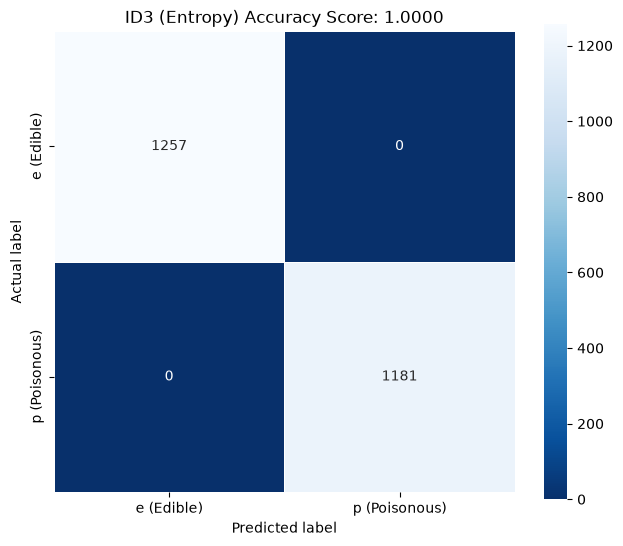

In [5]:
print(f"{STUDENT_NAME} - {MSSV}")

CLASS_LABELS = ["e", "p"]
id3_clf = tree.DecisionTreeClassifier(criterion="entropy", random_state=42)
id3_clf.fit(X_train, y_train)

id3_res = evaluate_and_plot_model(
    id3_clf,
    "ID3 (Entropy)",
    X_test,
    y_test,
    CLASS_LABELS,
    cmap="Blues_r",
)

Nguyễn Phạm Bảo Khanh - 6451071033


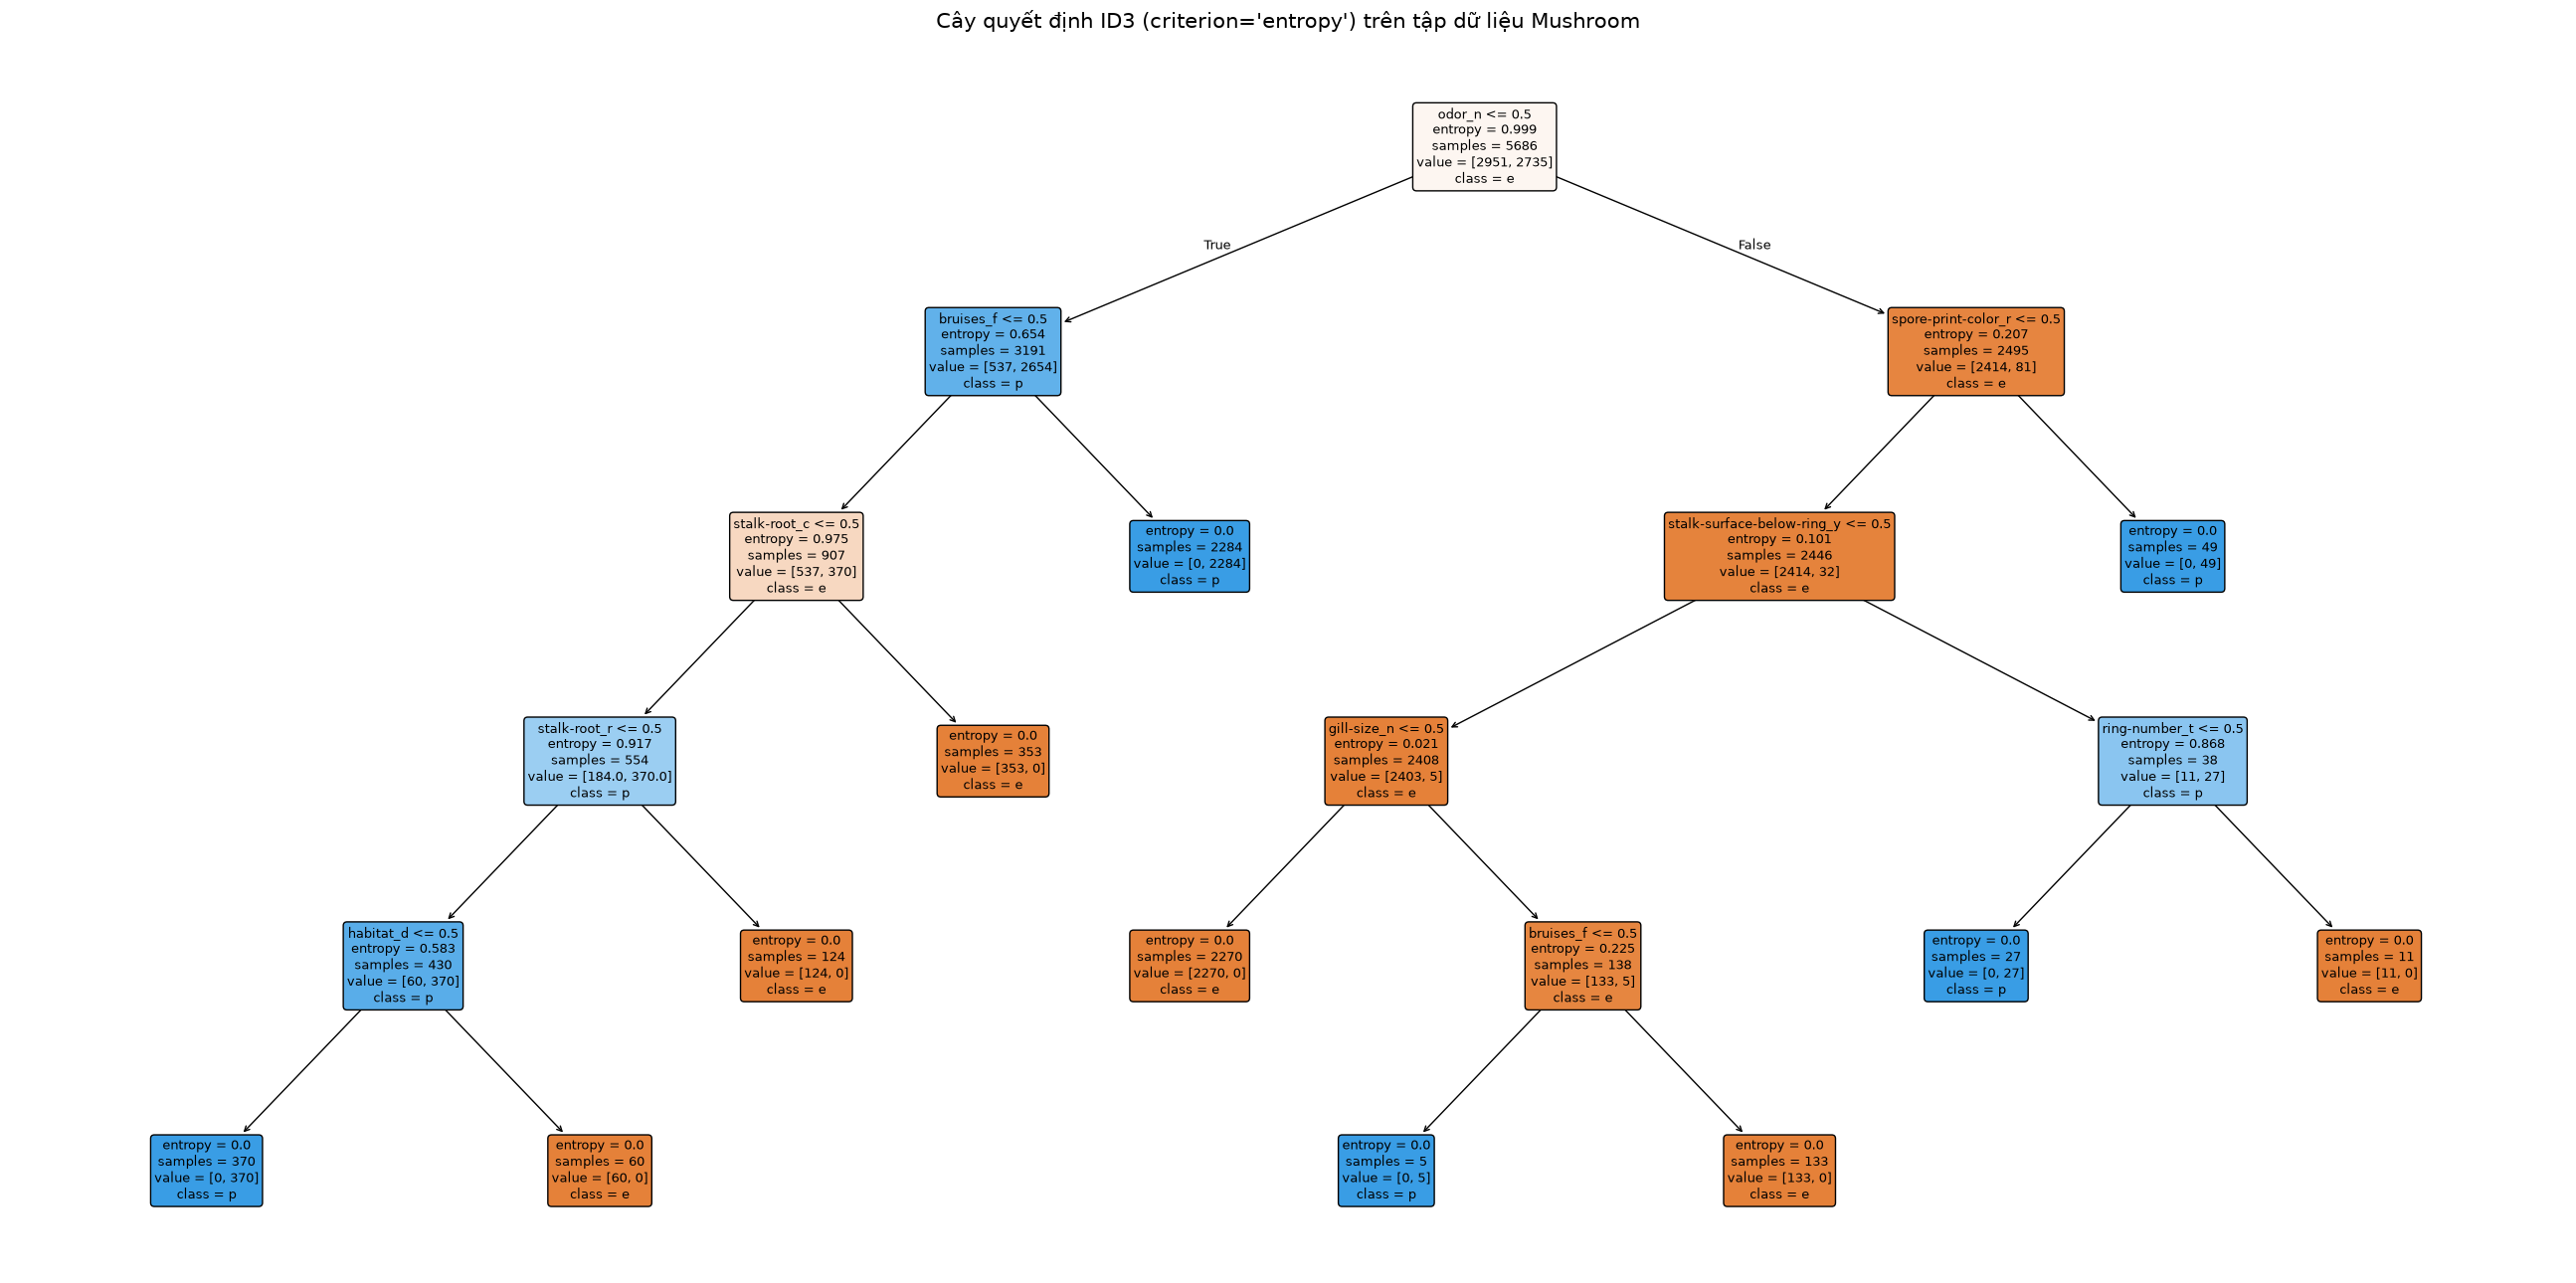

In [6]:
print(f"{STUDENT_NAME} - {MSSV}")

plot_decision_tree_figure(
    id3_clf,
    feature_names=features_onehot.columns,
    class_names=id3_clf.classes_,
    title="Cây quyết định ID3 (criterion='entropy') trên tập dữ liệu Mushroom",
    figsize=(26, 13),
)

## Câu 8: Xây dựng, kiểm thử và biểu diễn cây quyết định CART (`criterion='gini'`)

Nguyễn Phạm Bảo Khanh - 6451071033
=== Kết quả đánh giá mô hình CART (Gini) ===
Accuracy: 1.000000 (100.00%)
Độ sâu cây (depth): 7 | Số nút lá (leaves): 14

Classification Report:
              precision    recall  f1-score   support

           e     1.0000    1.0000    1.0000      1257
           p     1.0000    1.0000    1.0000      1181

    accuracy                         1.0000      2438
   macro avg     1.0000    1.0000    1.0000      2438
weighted avg     1.0000    1.0000    1.0000      2438

Confusion Matrix (rows=Actual ['e', 'p'], cols=Predicted ['e', 'p']):
[[1257    0]
 [   0 1181]]


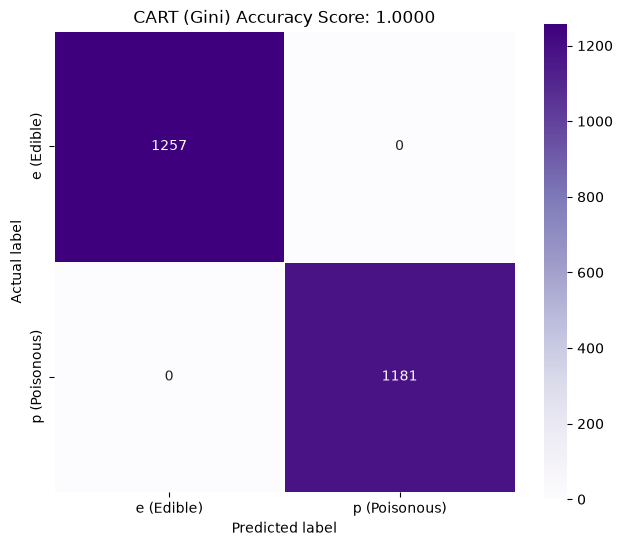

In [7]:
print(f"{STUDENT_NAME} - {MSSV}")

cart_clf = tree.DecisionTreeClassifier(criterion="gini", random_state=42)
cart_clf.fit(X_train, y_train)

cart_res = evaluate_and_plot_model(
    cart_clf,
    "CART (Gini)",
    X_test,
    y_test,
    CLASS_LABELS,
    cmap="Purples",
)

Nguyễn Phạm Bảo Khanh - 6451071033


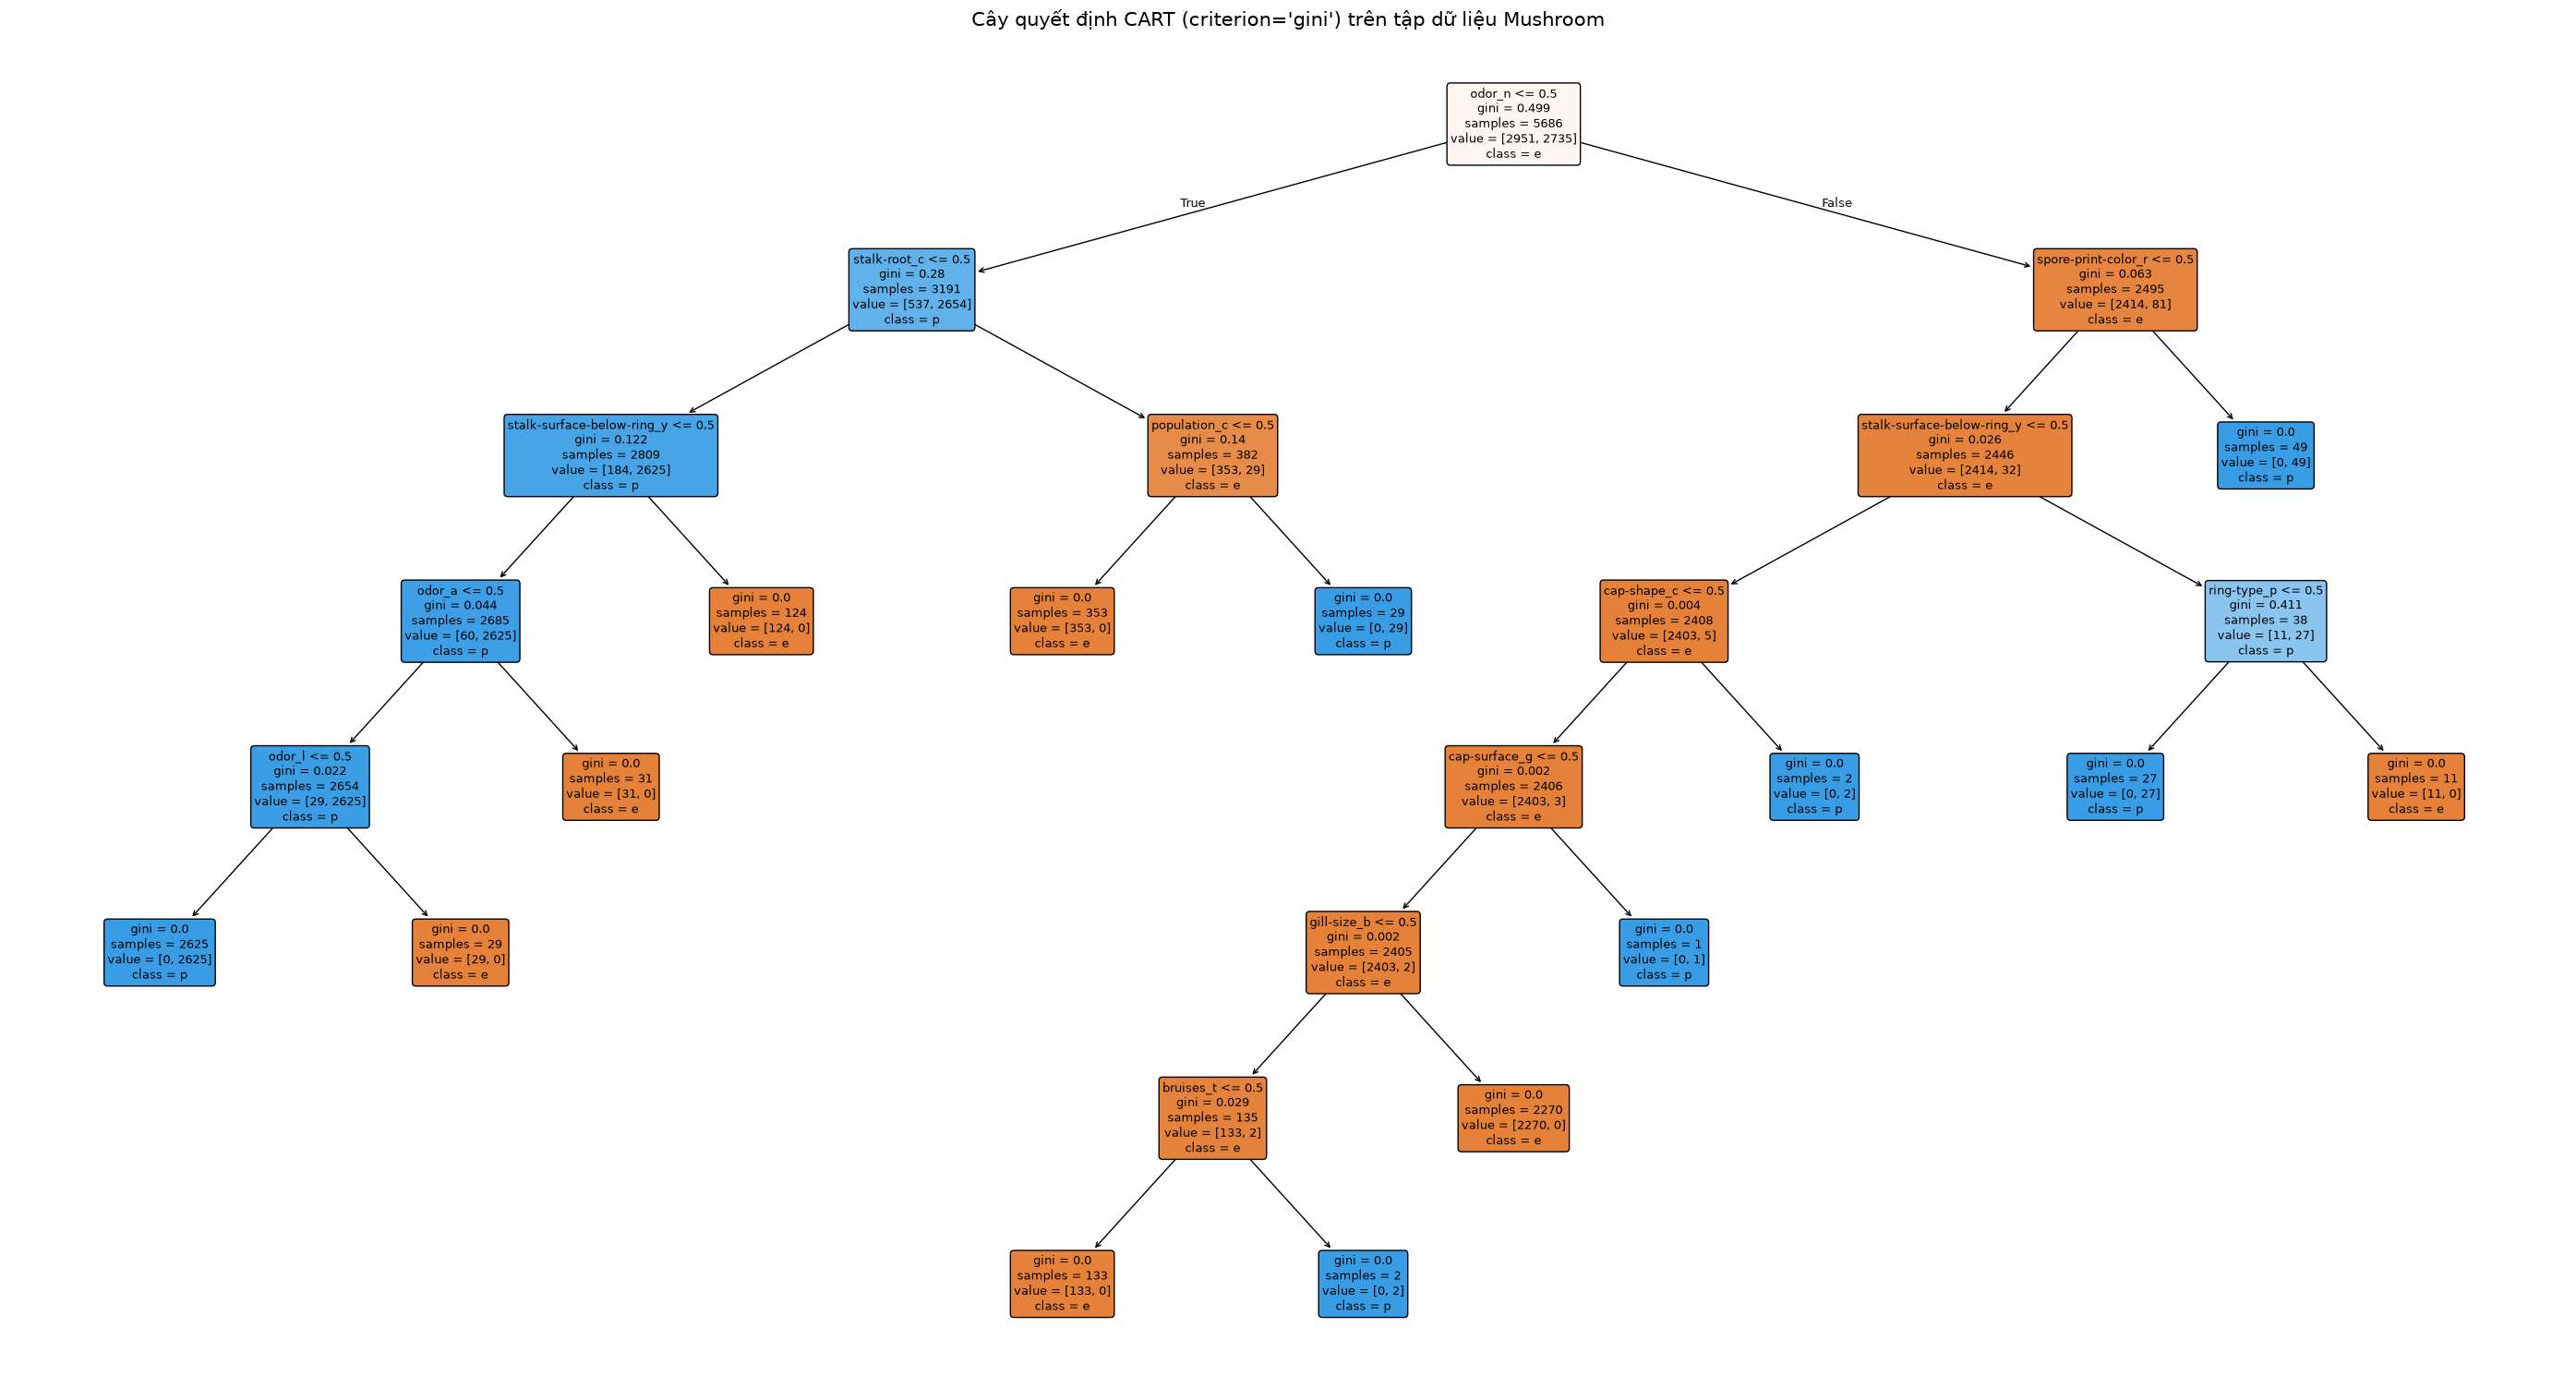

In [8]:
print(f"{STUDENT_NAME} - {MSSV}")

plot_decision_tree_figure(
    cart_clf,
    feature_names=features_onehot.columns,
    class_names=cart_clf.classes_,
    title="Cây quyết định CART (criterion='gini') trên tập dữ liệu Mushroom",
    figsize=(28, 15),
)

## Câu 9: Xây dựng và kiểm thử mô hình Naïve Bayes (`GaussianNB`)

Nguyễn Phạm Bảo Khanh - 6451071033
=== Kết quả đánh giá mô hình Gaussian Naïve Bayes ===
Accuracy: 0.964315 (96.43%)

Classification Report:
              precision    recall  f1-score   support

           e     0.9991    0.9316    0.9642      1257
           p     0.9321    0.9992    0.9644      1181

    accuracy                         0.9643      2438
   macro avg     0.9656    0.9654    0.9643      2438
weighted avg     0.9667    0.9643    0.9643      2438

Confusion Matrix (rows=Actual ['e', 'p'], cols=Predicted ['e', 'p']):
[[1171   86]
 [   1 1180]]


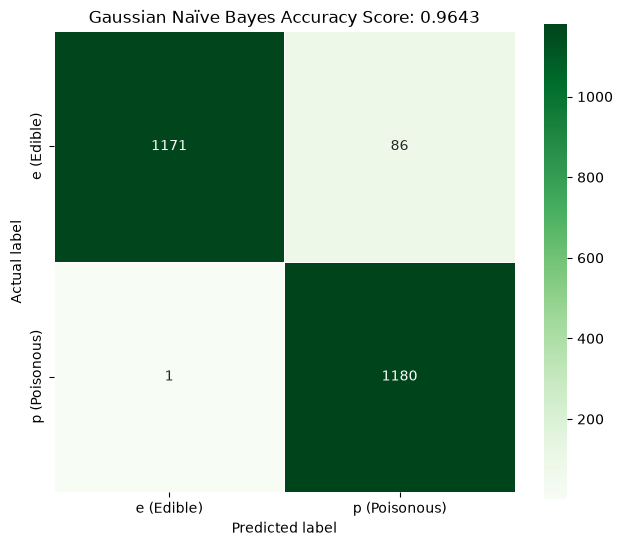

In [9]:
print(f"{STUDENT_NAME} - {MSSV}")

gnb_clf = GaussianNB()
gnb_clf.fit(X_train, y_train)

gnb_res = evaluate_and_plot_model(
    gnb_clf,
    "Gaussian Naïve Bayes",
    X_test,
    y_test,
    CLASS_LABELS,
    cmap="Greens",
)

## Câu 10: So sánh kết quả và nhận xét các mô hình

Nguyễn Phạm Bảo Khanh - 6451071033


,Mô hình,Accuracy,Precision (Macro),Recall (Macro),F1-Score (Macro),Precision (e),Recall (e),Precision (p),Recall (p),FP (e -> p),FN (p -> e)
0,ID3 (Entropy),1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,0,0
1,CART (Gini),1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,0,0
2,Gaussian Naïve Bayes,0.9643,0.9656,0.9654,0.9643,0.9991,0.9316,0.9321,0.9992,86,1


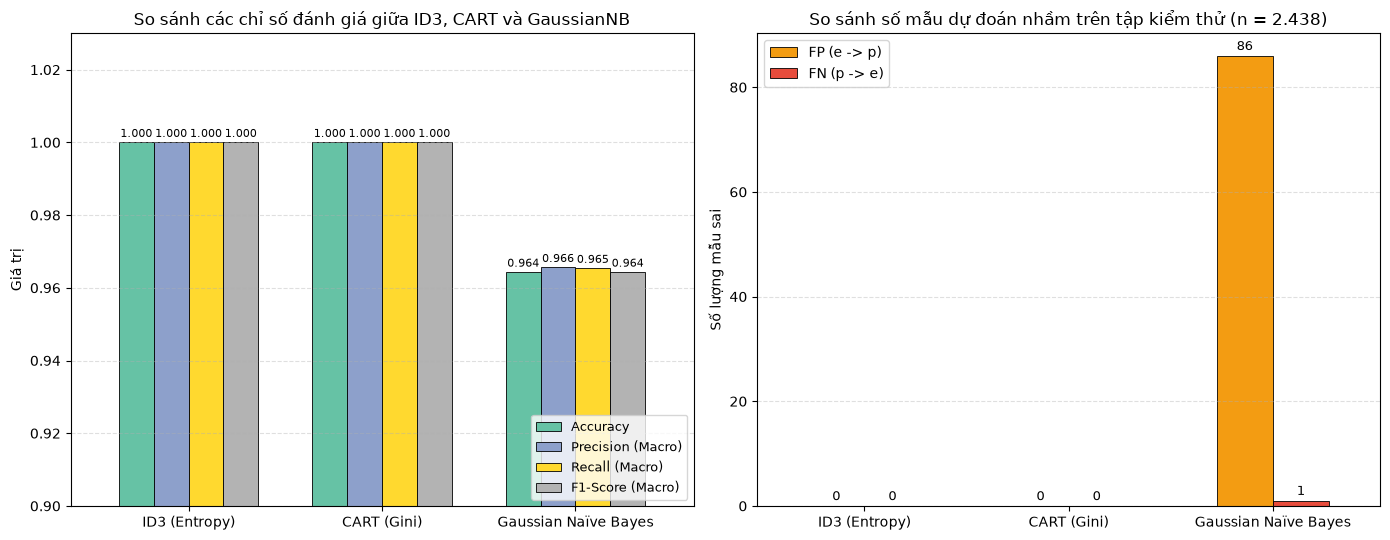

In [10]:
print(f"{STUDENT_NAME} - {MSSV}")

results_df = pd.DataFrame([
    {k: v for k, v in r.items() if k != "cm"}
    for r in (id3_res, cart_res, gnb_res)
])
display(results_df.round(4))

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

metrics_cols = ["Accuracy", "Precision (Macro)", "Recall (Macro)", "F1-Score (Macro)"]
plot_df = results_df.set_index("Mô hình")[metrics_cols]
plot_df.plot(kind="bar", ax=axes[0], width=0.72, colormap="Set2", edgecolor="black", linewidth=0.6)
axes[0].set_ylim(0.90, 1.03)
axes[0].set_title("So sánh các chỉ số đánh giá giữa ID3, CART và GaussianNB", fontsize=12)
axes[0].set_ylabel("Giá trị")
axes[0].set_xlabel("")
axes[0].tick_params(axis="x", rotation=0)
axes[0].legend(loc="lower right", fontsize=9)
axes[0].grid(axis="y", linestyle="--", alpha=0.4)
for container in axes[0].containers:
    axes[0].bar_label(container, fmt="%.3f", fontsize=8, padding=2)

err_df = results_df.set_index("Mô hình")[["FP (e -> p)", "FN (p -> e)"]]
err_df.plot(kind="bar", ax=axes[1], width=0.55, color=["#f39c12", "#e74c3c"], edgecolor="black", linewidth=0.6)
axes[1].set_title("So sánh số mẫu dự đoán nhầm trên tập kiểm thử (n = 2.438)", fontsize=12)
axes[1].set_ylabel("Số lượng mẫu sai")
axes[1].set_xlabel("")
axes[1].tick_params(axis="x", rotation=0)
axes[1].grid(axis="y", linestyle="--", alpha=0.4)
for container in axes[1].containers:
    axes[1].bar_label(container, fmt="%d", fontsize=9, padding=2)

plt.tight_layout()
plt.show()

### Nhận xét và phân tích kết quả (Câu 10)

1. **Hiệu năng vượt trội của cây quyết định (ID3 và CART đạt 100.00%):**
   - Cả **ID3 (`criterion='entropy'`)** và **CART (`criterion='gini'`)** đều đạt độ chính xác tuyệt đối **100.00%** (`2438/2438` mẫu đúng, Precision = Recall = F1 = `1.0000` cho cả hai lớp `e` và `p`).
   - Tập dữ liệu Mushroom có cấu trúc luật phân tách rất rõ ràng theo các thuộc tính phân loại đặc trưng (như `odor`, `spore-print-color`, `gill-size`, `stalk-root`), không có nhiễu nhãn nên cây quyết định dễ dàng tìm ra các điều kiện rẽ nhánh nhị phân trên vector one-hot để tách sạch hai lớp.
   - Cây **ID3** có cấu trúc gọn hơn (**độ sâu 5, 11 nút lá**) so với **CART** (**độ sâu 7, 14 nút lá**), cho thấy tiêu chuẩn Information Gain chọn được các nhánh chia ở tầng trên cô đọng hơn một chút trong bài toán này.

2. **Tại sao `GaussianNB` đạt `96.43%` (thấp hơn ID3 và CART) trên dữ liệu One-Hot?**
   - **Vi phạm giả định độc lập có điều kiện:** Mã hóa one-hot biến mỗi thuộc tính phân loại ban đầu thành một nhóm các cột nhị phân loại trừ lẫn nhau (trong cùng một thuộc tính gốc, đúng 1 cột mang giá trị `1` và các cột còn lại mang giá trị `0`), tạo ra tương quan âm rất mạnh giữa các cột cùng nhóm và phá vỡ giả định độc lập giữa các đặc trưng của Naïve Bayes.
   - **Không khớp phân phối xác suất của `GaussianNB`:** `GaussianNB` giả định từng đặc trưng tuân theo phân phối chuẩn $\mathcal{N}(\mu, \sigma^2)$, trong khi các cột one-hot thực chất là biến nhị phân rời rạc `{0, 1}`. Với các giá trị hiếm chỉ xuất hiện ở một lớp, phương sai ước lượng rất nhỏ khiến mật độ Gaussian phạt nặng khi gặp mẫu kiểm thử có đặc trưng ít gặp (trong thực tế, `BernoulliNB` hoặc `CategoricalNB` phù hợp hơn cho dữ liệu nhị phân/phân loại).
   - **Phân tích lỗi của `GaussianNB`:** Trong tổng số **87 mẫu sai** trên 2.438 mẫu kiểm thử, có tới **86 mẫu** là nấm ăn được (`e`) bị dự đoán nhầm thành nấm độc (`p`) và chỉ **1 mẫu** nấm độc (`p`) bị dự đoán nhầm thành ăn được (`e`) (Recall của lớp `p` đạt `99.92%`). Dù độ chính xác tổng thể vẫn cao (`96.43%`), hai mô hình cây quyết định **ID3** và **CART** vẫn là lựa chọn tối ưu hoàn toàn cho tập dữ liệu Mushroom.